# **Parte A. Modelo y datos**

- Importar librerías.
- Leer Train.csv y Test.csv.
- Crear Dataset y DataLoader.
- Redimensionar a 32x32.
- Crear arquitectura.
- Entrenar modelo.
- Ejecutar inferencia limpia.
- Calcular accuracy y matriz de confusión.

In [164]:
import socket
import sys
import torch

print("Host:", socket.gethostname())
print("Python:", sys.executable)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Host: Silver
Python: F:\remote-python\envs\ml\.venv\Scripts\python.exe
CUDA: True
GPU: NVIDIA GeForce RTX 3060


In [165]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm

In [166]:
SEED = 13

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else print("no hay cuda"))
print(device)

cuda


In [167]:
import os
print(os.getcwd())

DATASET_ROOT = Path(r"\\192.168.0.34\linux_home\Documentos\Uni\Sistemas de Inteligencia Artificial Ciberseguros\p1\data\dataset")
#100.x.x.x tailscale envyx360
print(os.listdir(DATASET_ROOT))

IMAGE_SIZE = 32
NUM_CLASSES = 43
BATCH_SIZE = 128
NUM_WORKERS = 0

MODEL_PATH = DATASET_ROOT.parent / "gtsrb_cnn.pth"

F:\remote-python\envs\ml
['archive.zip', 'Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


In [168]:
#Read CSVs
train_df = pd.read_csv(DATASET_ROOT / "Train.csv")
test_df = pd.read_csv(DATASET_ROOT / "Test.csv")

train_df["filepath"] = train_df["Path"].map(lambda path: DATASET_ROOT / path)
test_df["filepath"] = test_df["Path"].map(lambda path: DATASET_ROOT / path)
pd.set_option('display.max_colwidth', None)
print(train_df.shape)
print(test_df.shape)
print(train_df.head())
print(train_df["ClassId"].nunique())

(39209, 9)
(12630, 9)
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  \
0  Train/20/00020_00000_00000.png   
1  Train/20/00020_00000_00001.png   
2  Train/20/00020_00000_00002.png   
3  Train/20/00020_00000_00003.png   
4  Train/20/00020_00000_00004.png   

                                                                                                                                   filepath  
0  \\192.168.0.34\linux_home\Documentos\Uni\Sistemas de Inteligencia Artificial Ciberseguros\p1\data\dataset\Train\20\00020_00000_00000.png  
1  \\192.168.0.34\linux_home\Documentos\Uni\Sistemas de Inteligencia Artificial Ciberseguros\p1\data\dat

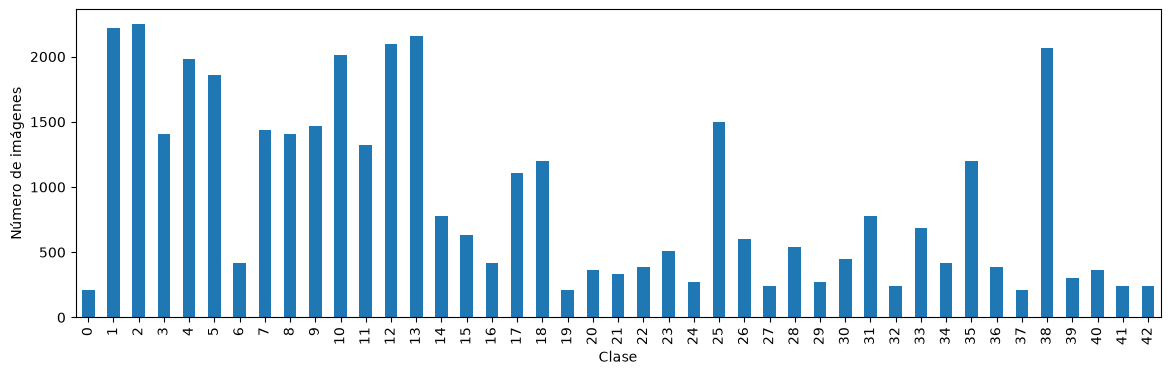

In [169]:
#Dataset info
train_df["ClassId"].value_counts().sort_index().plot.bar(figsize=(14, 4))
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.show()

In [170]:
#Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    ),
])

In [171]:
#Validation transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    ),
])

In [172]:
#Dataset class creation
class GTSRBDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True) #viene de dataframe
        self.transform = transform #tiene una trasnforamcion asociada dicho subconjunto

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index] #returns value in this index

        image = Image.open(row["filepath"]).convert("RGB")
        label = int(row["ClassId"])

        if self.transform is not None:
            image = self.transform(image) #transforms if selected

        return image, label

In [173]:
#Train Val separation
indices = np.arange(len(train_df))
np.random.shuffle(indices)

split = int(0.8 * len(indices))

train_indices = indices[:split]
validation_indices = indices[split:]

train_subset_df = train_df.iloc[train_indices]
validation_subset_df = train_df.iloc[validation_indices]

In [174]:
#Train, Val, Test datasets creation
train_dataset = GTSRBDataset(train_subset_df,transform=train_transform)
validation_dataset = GTSRBDataset(validation_subset_df,transform=eval_transform)
test_dataset = GTSRBDataset(test_df,transform=eval_transform)

In [175]:
#DataLoader creation
TEST_BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

In [176]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)
print(images.min().item(), images.max().item())

torch.Size([128, 3, 32, 32])
torch.Size([128])
-1.0 1.0


In [177]:
# CNN architecture
class TrafficSignCNN(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), #RGB (3) 32x32 -> (32) 32x32 -> (32) 16x16 -> (64) 16x16 -> (64) 8x8 -> (128) 8x8 -> (128) 4x4
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),   #(128) 4x4 -> [2048]
            nn.Linear(128 * 4 * 4, 256), #capa FC de 256 neuronas
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )
    #Imagen:              [3, 32, 32]
    #features:            [128, 4, 4]
    #Flatten:             [2048]
    #Linear:              [256]
    #Linear final:        [43] clases
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = TrafficSignCNN(NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += labels.size(0)

    return total_loss / total_examples, total_correct / total_examples


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += labels.size(0)
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            targets.extend(labels.cpu().numpy())

    return (
        total_loss / total_examples,
        total_correct / total_examples,
        np.asarray(predictions),
        np.asarray(targets),
    )

print(model)

TrafficSignCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=43, bias=True)
  )
)


In [178]:
# Train the CNN and keep the best validation checkpoint

NUM_EPOCHS = 15
best_validation_accuracy = 0.0
history = []

TRAIN = False
if TRAIN:
    for epoch in range(NUM_EPOCHS):
        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )
        validation_loss, validation_accuracy, _, _ = evaluate(
            model, validation_loader, criterion, device
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
        })

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            torch.save(model.state_dict(), MODEL_PATH)

        print(
            f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
            f"train loss {train_loss:.4f} | train acc {train_accuracy:.4f} | "
            f"val loss {validation_loss:.4f} | val acc {validation_accuracy:.4f}"
        )

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

history_df = pd.DataFrame(history)
print(f"Best validation accuracy: {best_validation_accuracy:.4f}")

Best validation accuracy: 0.0000


# **Parte B-1. Implementación FGSM**

Images evaluated: 128


Clean accuracy on one batch: 0.8828
              precision    recall  f1-score   support

           1       1.00      0.88      0.93         8
           2       1.00      1.00      1.00         4
           3       0.75      0.86      0.80         7
           4       0.83      1.00      0.91         5
           5       1.00      0.60      0.75         5
           7       0.80      0.67      0.73         6
           8       0.75      1.00      0.86         3
           9       1.00      1.00      1.00         8
          10       1.00      1.00      1.00         9
          11       0.62      1.00      0.77         5
          12       1.00      1.00      1.00         6
          13       1.00      1.00      1.00         5
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         4
          17       1.00      1.00      1.00         3
          18       1.00      0.67      0.80  

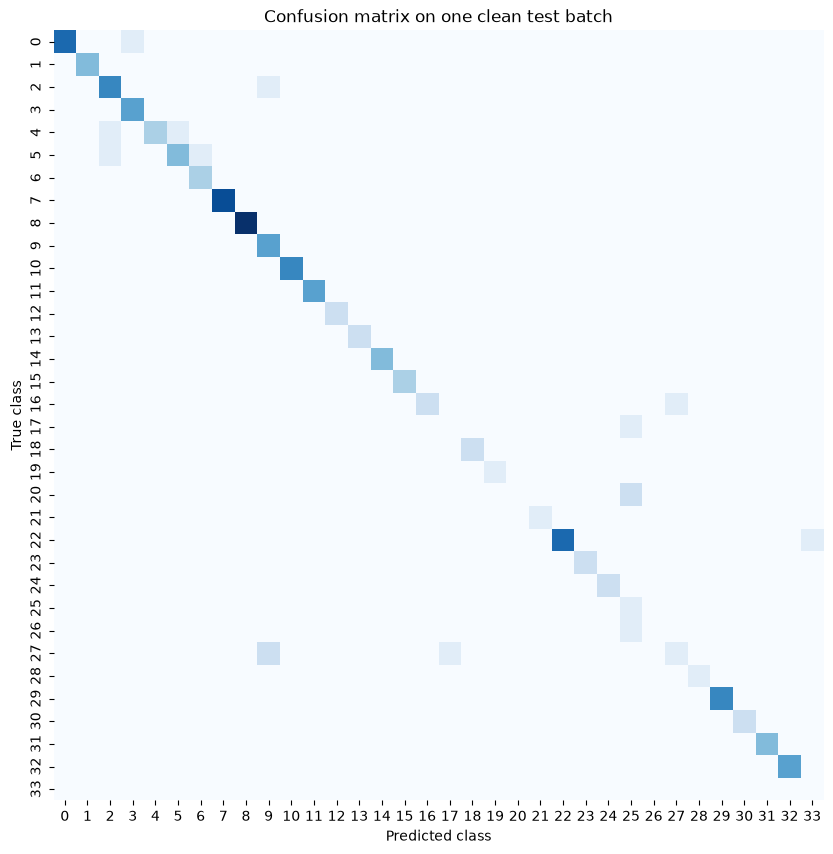

,epsilon,clean_accuracy,adversarial_accuracy,attack_success_rate,mean_l2,mean_linf
0,0.00,0.882812,0.882812,0.000000,0.000000,0.00
1,0.01,0.882812,0.492188,0.442478,1.100481,0.02
2,0.03,0.882812,0.117188,0.867257,3.295843,0.06
3,0.05,0.882812,0.046875,0.946903,5.470088,0.10
4,0.10,0.882812,0.039062,0.955752,10.668364,0.20
5,0.20,0.882812,0.031250,0.964602,20.049362,0.40


In [179]:
# Evaluate the clean model and define FGSM
# Evaluate only one test batch instead of the complete test set.
one_test_batch = [next(iter(test_loader))]
print(f"Images evaluated: {one_test_batch[0][0].size(0)}")

clean_loss, clean_accuracy, clean_predictions, clean_targets = evaluate(model, one_test_batch, criterion, device)
print(f"Clean accuracy on one batch: {clean_accuracy:.4f}")
print(classification_report(clean_targets, clean_predictions, zero_division=0))

confusion = confusion_matrix(clean_targets, clean_predictions)
plt.figure(figsize=(12, 10))
sns.heatmap(confusion, cmap="Blues", square=True, cbar=False)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix on one clean test batch")
plt.show()

def fgsm_attack(model, images, labels, epsilon, criterion, device):
    model.eval()

    normalized_images = images.detach().clone().to(device)
    normalized_images.requires_grad_(True)
    labels = labels.to(device)

    model.zero_grad(set_to_none=True)

    logits = model(normalized_images)
    loss = criterion(logits, labels)
    loss.backward()

    data_gradient = normalized_images.grad.sign()

    mean = torch.tensor(
        [0.5, 0.5, 0.5],
        device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.5, 0.5, 0.5],
        device=device
    ).view(1, 3, 1, 1)

    # denorm
    original_images = normalized_images * std + mean

    # Perturbacion epsilon en el espacio original de pixeles
    adversarial_images = original_images + epsilon * data_gradient
    adversarial_images = torch.clamp(adversarial_images, 0.0, 1.0)

    # norm
    adversarial_images = (adversarial_images - mean) / std

    return adversarial_images.detach()

def evaluate_fgsm(model, loader, criterion, epsilon, device):
    model.eval()
    total = 0
    clean_correct = 0
    adversarial_correct = 0
    successful_attacks = 0
    l2_values = []
    linf_values = []

    for images, labels in tqdm(loader, desc=f"Evaluating FGSM (epsilon={epsilon})", leave=False):
        images = images.to(device)
        labels = labels.to(device)

        with torch.no_grad():
            clean_predictions = model(images).argmax(dim=1)

        adversarial_images = fgsm_attack(
            model, images, labels, epsilon, criterion, device
        )
        with torch.no_grad():
            adversarial_predictions = model(adversarial_images).argmax(dim=1)

        correctly_classified = clean_predictions == labels
        clean_correct += correctly_classified.sum().item()
        adversarial_correct += (adversarial_predictions == labels).sum().item()
        successful_attacks += (
            correctly_classified
            & (adversarial_predictions != labels)
        ).sum().item()
        total += labels.size(0)

        difference = adversarial_images - images
        l2_values.extend(difference.flatten(1).norm(p=2, dim=1).cpu().numpy())
        linf_values.extend(difference.flatten(1).abs().max(dim=1).values.cpu().numpy())

    return {
        "epsilon": epsilon,
        "clean_accuracy": clean_correct / total,
        "adversarial_accuracy": adversarial_correct / total,
        "attack_success_rate": successful_attacks / max(clean_correct, 1),
        "mean_l2": float(np.mean(l2_values)),
        "mean_linf": float(np.mean(linf_values)),
    }


fgsm_results = pd.DataFrame([
    evaluate_fgsm(model, one_test_batch, criterion, epsilon, device) for epsilon in [0.0, 0.01, 0.03, 0.05, 0.1, 0.2]
])
fgsm_results

In [180]:
# FGSM targeted: mismo algoritmo, pero dirigido a la clase 33
FGSM_TARGET_CLASS = 33


def fgsm_targeted_attack(model, images, target_labels, epsilon, device):
    model.eval()
    normalized_images = images.detach().clone().to(device)
    normalized_images.requires_grad_(True)
    target_labels = target_labels.to(device)

    model.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(normalized_images), target_labels)
    loss.backward()

    mean = torch.tensor([0.5, 0.5, 0.5], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.5, 0.5, 0.5], device=device).view(1, 3, 1, 1)
    original_images = normalized_images * std + mean
    adversarial_images = original_images - epsilon * normalized_images.grad.sign()
    adversarial_images = torch.clamp(adversarial_images, 0.0, 1.0)
    return ((adversarial_images - mean) / std).detach()


def evaluate_fgsm_targeted(model, loader, epsilon, target_class, device):
    model.eval()
    total = 0
    targeted_successes = 0

    for images, labels in loader:
        images = images.to(device)
        target_labels = torch.full_like(labels, target_class, device=device)
        adversarial_images = fgsm_targeted_attack(
            model, images, target_labels, epsilon, device
        )
        with torch.no_grad():
            predictions = model(adversarial_images).argmax(dim=1)

        targeted_successes += (predictions == target_labels).sum().item()
        total += labels.size(0)

    return {
        "epsilon": epsilon,
        "target_class": target_class,
        "targeted_attack_success_rate": targeted_successes / total,
    }


fgsm_targeted_results = pd.DataFrame([
    evaluate_fgsm_targeted(
        model,
        one_test_batch,
        epsilon,
        FGSM_TARGET_CLASS,
        device,
    )
    for epsilon in [0.01, 0.03, 0.05, 0.10, 0.20]
])
fgsm_targeted_results

,epsilon,target_class,targeted_attack_success_rate
0,0.01,33,0.078125
1,0.03,33,0.164062
2,0.05,33,0.210938
3,0.10,33,0.296875
4,0.20,33,0.265625


# **Parte B-2. Implementación RP2**
- fase 1, localizar regiones vulnerables dentro de ROI de la imagen del objeto
    - convertir regiones vulnerables en máscara
- fase 2, optmizar parche fijo en esa máscara
    - crear transformaciones que simulen condiciones reales
- evaluar RP2

RP2 images selected: 128 (1 batch(es) x 128 images)


RP2 stage 1: 100%|██████████| 1000/1000 [00:05<00:00, 173.56it/s]


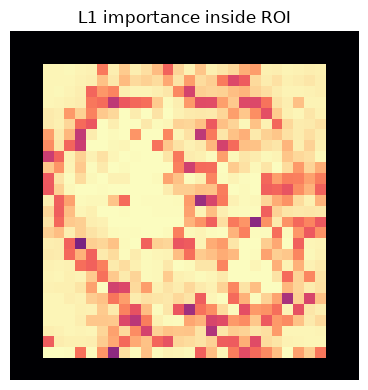

RP2 optimization finished for all patch areas


In [181]:
# RP2: two-stage shared perturbation restricted to the sign ROI
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

TARGET_CLASS = 33
RP2_IMAGES_PER_BATCH = 128
RP2_NUM_BATCHES = 1
RP2_BATCH_SIZE = RP2_IMAGES_PER_BATCH * RP2_NUM_BATCHES
RP2_EPOCHS_STAGE_1 = 1000
RP2_EPOCHS_STAGE_2 = 1000
RP2_PATCH_AREAS = [0.30, 0.20, 0.15, 0.10, 0.05]
RP2_LAMBDA_L1 = 0.001
RP2_LAMBDA_L2 = 0.001


def get_attack_batch(dataframe, target_class, batch_size, image_size, device):
    selected_images = []
    selected_labels = []
    selected_masks = []

    for _, row in dataframe.iterrows():
        if int(row["ClassId"]) == target_class:
            continue

        image = Image.open(row["filepath"]).convert("RGB")
        image = eval_transform(image)

        mask = torch.zeros(1, image_size, image_size)
        x1 = int(round(float(row["Roi.X1"]) * image_size / float(row["Width"])))
        y1 = int(round(float(row["Roi.Y1"]) * image_size / float(row["Height"])))
        x2 = int(round(float(row["Roi.X2"]) * image_size / float(row["Width"])))
        y2 = int(round(float(row["Roi.Y2"]) * image_size / float(row["Height"])))

        x1 = max(0, min(x1, image_size - 1))
        y1 = max(0, min(y1, image_size - 1))
        x2 = max(x1 + 1, min(x2, image_size))
        y2 = max(y1 + 1, min(y2, image_size))
        mask[:, y1:y2, x1:x2] = 1.0

        selected_images.append(image)
        selected_labels.append(int(row["ClassId"]))
        selected_masks.append(mask)

        if len(selected_images) >= batch_size:
            break

    images = torch.stack(selected_images).to(device)
    labels = torch.tensor(selected_labels, dtype=torch.long, device=device)
    masks = torch.stack(selected_masks).to(device)
    return images, labels, masks


def apply_patch(images, delta, mask):
    patched_images = images + mask * delta
    return torch.clamp(patched_images, -1.0, 1.0)


def total_variation(patch):
    vertical = (patch[:, :, 1:, :] - patch[:, :, :-1, :]).abs().mean()
    horizontal = (patch[:, :, :, 1:] - patch[:, :, :, :-1]).abs().mean()
    return vertical + horizontal


def random_physical_transform(images):
    transformed = []
    for image in images:
        angle = float(torch.empty(1).uniform_(-15.0, 15.0).item())
        translate = [
            int(torch.empty(1).uniform_(-2.0, 2.0).item()),
            int(torch.empty(1).uniform_(-2.0, 2.0).item()),
        ]
        scale = float(torch.empty(1).uniform_(0.90, 1.10).item())
        transformed_image = TF.affine(
            image,
            angle=angle,
            translate=translate,
            scale=scale,
            shear=[0.0, 0.0],
            interpolation=InterpolationMode.BILINEAR,
            fill=0.0,
        )
        contrast = float(torch.empty(1).uniform_(0.85, 1.15).item())
        transformed_image = transformed_image * contrast
        transformed.append(torch.clamp(transformed_image, -1.0, 1.0))
    return torch.stack(transformed)


attack_images, attack_labels, object_masks = get_attack_batch(
    test_df, TARGET_CLASS, RP2_BATCH_SIZE, IMAGE_SIZE, device
)
print(
    f"RP2 images selected: {len(attack_images)} "
    f"({RP2_NUM_BATCHES} batch(es) x {RP2_IMAGES_PER_BATCH} images)"
)
target_labels = torch.full_like(attack_labels, TARGET_CLASS)
mask_full = object_masks

# Stage 1: search for vulnerable regions only inside each sign region of interest (ROI)
delta_stage_1 = torch.zeros(
    1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device, requires_grad=True
)
optimizer_stage_1 = optim.Adam([delta_stage_1], lr=0.25, eps=0.0001)
stage_1_history = []

for epoch in tqdm(range(RP2_EPOCHS_STAGE_1), desc="RP2 stage 1"):
    optimizer_stage_1.zero_grad()
    patched_images = apply_patch(attack_images, delta_stage_1, mask_full)
    logits = model(patched_images)
    classification_loss = F.cross_entropy(logits, target_labels)
    l1_loss = (mask_full * delta_stage_1).abs().mean()
    loss = classification_loss + RP2_LAMBDA_L1 * l1_loss
    loss.backward()
    optimizer_stage_1.step()
    with torch.no_grad():
        delta_stage_1.clamp_(-1.0, 1.0)

    stage_1_history.append({
        "epoch": epoch + 1,
        "loss": loss.item(),
        "classification_loss": classification_loss.item(),
        "targeted_accuracy": (logits.argmax(dim=1) == target_labels).float().mean().item(),
    })

# Aggregate the shared perturbation's importance before selecting each patch area.
importance = delta_stage_1.detach().abs().sum(dim=1, keepdim=True)
importance = importance * (object_masks.max(dim=0, keepdim=True).values > 0).float()
importance = importance / (importance.max() + 1e-8)
roi_importance = importance[importance > 0]

fig, axis = plt.subplots(figsize=(4, 4))
axis.imshow(importance[0, 0].cpu(), cmap="magma")
axis.set_title("L1 importance inside ROI")
axis.axis("off")
plt.tight_layout()
plt.show()

# Stage 2: optimize one independent shared patch for every selected area.
rp2_patches = {}
rp2_masks = {}
rp2_stage_2_histories = {}

for patch_area in RP2_PATCH_AREAS:
    threshold = torch.quantile(roi_importance, 1.0 - patch_area)
    patch_mask = (importance >= threshold).float().repeat(1, 3, 1, 1).detach()
    delta_patch = (patch_mask * delta_stage_1.detach()).clone().requires_grad_(True)
    patch_optimizer = optim.Adam([delta_patch], lr=0.25, eps=0.0001)
    patch_history = []

    for epoch in tqdm(
        range(RP2_EPOCHS_STAGE_2),
        desc=f"RP2 stage 2 ({patch_area:.0%} ROI)",
        leave=False,
    ):
        patch_optimizer.zero_grad()
        patched_images = apply_patch(attack_images, delta_patch, patch_mask)
        transformed_images = random_physical_transform(patched_images)
        logits = model(transformed_images)
        classification_loss = F.cross_entropy(logits, target_labels)
        masked_patch = patch_mask * delta_patch
        l2_loss = masked_patch.pow(2).mean()
        loss = classification_loss + RP2_LAMBDA_L2 * l2_loss
        loss.backward()
        patch_optimizer.step()
        with torch.no_grad():
            delta_patch.clamp_(-1.0, 1.0)

        patch_history.append({
            "patch_area": patch_area,
            "epoch": epoch + 1,
            "loss": loss.item(),
            "classification_loss": classification_loss.item(),
            "targeted_accuracy": (
                (logits.argmax(dim=1) == target_labels).float().mean().item()
            ),
        })

    rp2_masks[patch_area] = patch_mask
    rp2_patches[patch_area] = (patch_mask * delta_patch).detach()
    rp2_stage_2_histories[patch_area] = pd.DataFrame(patch_history)

stage_1_history = pd.DataFrame(stage_1_history)
stage_2_history = pd.concat(rp2_stage_2_histories.values(), ignore_index=True)
vulnerable_mask = rp2_masks[RP2_PATCH_AREAS[0]]
final_patch = rp2_patches[RP2_PATCH_AREAS[0]]
print("RP2 optimization finished for all patch areas")

In [182]:
# Calculo de la comparacion comun despues de generar RP2

def summarize_attack(name, clean_predictions, adversarial_predictions, labels, targets):
    clean_correct = clean_predictions == labels
    return {
        "method": name,
        "targeted_success": (adversarial_predictions == targets).float().mean().item(),
        "untargeted_success": (
            (clean_correct & (adversarial_predictions != labels)).sum().item()
            / max(clean_correct.sum().item(), 1)
        ),
        "adversarial_accuracy": (adversarial_predictions == labels).float().mean().item(),
    }


comparison_images = attack_images
comparison_labels = attack_labels
comparison_targets = target_labels
with torch.no_grad():
    comparison_clean_predictions = model(comparison_images).argmax(dim=1)

comparison_fgsm_u = fgsm_attack(
    model,
    comparison_images,
    comparison_labels,
    FGSM_COMPARISON_EPSILON,
    criterion,
    device,
)
comparison_fgsm_t = fgsm_targeted_attack(
    model,
    comparison_images,
    comparison_targets,
    FGSM_COMPARISON_EPSILON,
    device,
)
comparison_rp2 = apply_patch(
    comparison_images,
    final_patch,
    vulnerable_mask,
)

with torch.no_grad():
    comparison_fgsm_u_predictions = model(comparison_fgsm_u).argmax(dim=1)
    comparison_fgsm_t_predictions = model(comparison_fgsm_t).argmax(dim=1)
    comparison_rp2_predictions = model(comparison_rp2).argmax(dim=1)

attack_comparison = pd.DataFrame([
    summarize_attack(
        "FGSM untargeted",
        comparison_clean_predictions,
        comparison_fgsm_u_predictions,
        comparison_labels,
        comparison_targets,
    ),
    summarize_attack(
        "FGSM targeted -> 33",
        comparison_clean_predictions,
        comparison_fgsm_t_predictions,
        comparison_labels,
        comparison_targets,
    ),
    summarize_attack(
        "RP2 targeted -> 33",
        comparison_clean_predictions,
        comparison_rp2_predictions,
        comparison_labels,
        comparison_targets,
    ),
])

IIb: resultados según el tamaño del parche candidato


,patch_area_fraction,mean_targeted_accuracy,worst_condition_targeted_accuracy
0,0.05,0.1391,0.1016
1,0.10,0.5531,0.3359
2,0.15,0.7609,0.6250
3,0.20,0.8500,0.7188
4,0.30,0.9594,0.8906


Menor tamaño consistente: 15% del ROI.


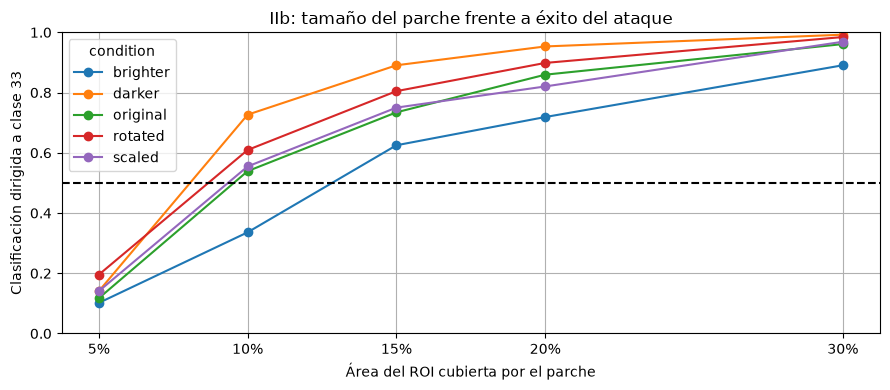

In [183]:
# IIb: influencia del tamaño del parche RP2
# Se reutiliza la importancia de la fase 1 para construir parches candidatos
# de distintos tamaños. La robustez final de RP2 se evalua en la demostracion de IIc.

PATCH_AREA_FRACTIONS = RP2_PATCH_AREAS
CONSISTENT_TARGETED_THRESHOLD = 0.50

roi_mask = (object_masks.max(dim=0, keepdim=True).values > 0).float()
importance_map = delta_stage_1.detach().abs().sum(dim=1, keepdim=True) * roi_mask
importance_values = importance_map[roi_mask.bool()]


def get_deterministic_conditions(images):
    return {
        "original": images,
        "rotated": TF.affine(
            images, angle=15.0, translate=[0, 0], scale=1.0,
            shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR,
            fill=0.0,
        ),
        "darker": torch.clamp(images * 0.75, -1.0, 1.0),
        "brighter": torch.clamp(images * 1.25, -1.0, 1.0),
        "scaled": TF.affine(
            images, angle=0.0, translate=[0, 0], scale=1.10,
            shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR,
            fill=0.0,
        ),
    }


size_results = []
model.eval()
for area_fraction in PATCH_AREA_FRACTIONS:
    size_mask = rp2_masks[area_fraction]
    size_patch = rp2_patches[area_fraction]

    for condition, condition_images in get_deterministic_conditions(attack_images).items():
        patched_images = apply_patch(condition_images, size_patch, size_mask)
        with torch.no_grad():
            predictions = model(patched_images).argmax(dim=1)

        size_results.append({
            "patch_area_fraction": area_fraction,
            "condition": condition,
            "targeted_accuracy": (predictions == target_labels).float().mean().item(),
        })

rp2_size_results = pd.DataFrame(size_results)
rp2_size_summary = rp2_size_results.groupby(
    "patch_area_fraction", as_index=False
).agg(
    mean_targeted_accuracy=("targeted_accuracy", "mean"),
    worst_condition_targeted_accuracy=("targeted_accuracy", "min"),
)

consistent_sizes = rp2_size_summary.loc[
    rp2_size_summary["worst_condition_targeted_accuracy"] >= CONSISTENT_TARGETED_THRESHOLD,
    "patch_area_fraction",
]
smallest_consistent_size = float(consistent_sizes.iloc[0]) if len(consistent_sizes) else None

print("IIb: resultados según el tamaño del parche candidato")
display(rp2_size_summary.round(4))
print(
    "Menor tamaño consistente: "
    f"{smallest_consistent_size:.0%} del ROI."
    if smallest_consistent_size is not None
    else "No se encontro un tamaño consistente con el umbral definido."
)

rp2_size_plot = rp2_size_results.pivot(
    index="patch_area_fraction",
    columns="condition",
    values="targeted_accuracy",
)
rp2_size_plot.plot(marker="o", figsize=(9, 4))
plt.axhline(CONSISTENT_TARGETED_THRESHOLD, color="black", linestyle="--")
plt.xlabel("Área del ROI cubierta por el parche")
plt.ylabel("Clasificación dirigida a clase 33")
plt.title("IIb: tamaño del parche frente a éxito del ataque")
plt.xticks(PATCH_AREA_FRACTIONS, [f"{value:.0%}" for value in PATCH_AREA_FRACTIONS])
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

# Comparación FGSM vs RP2

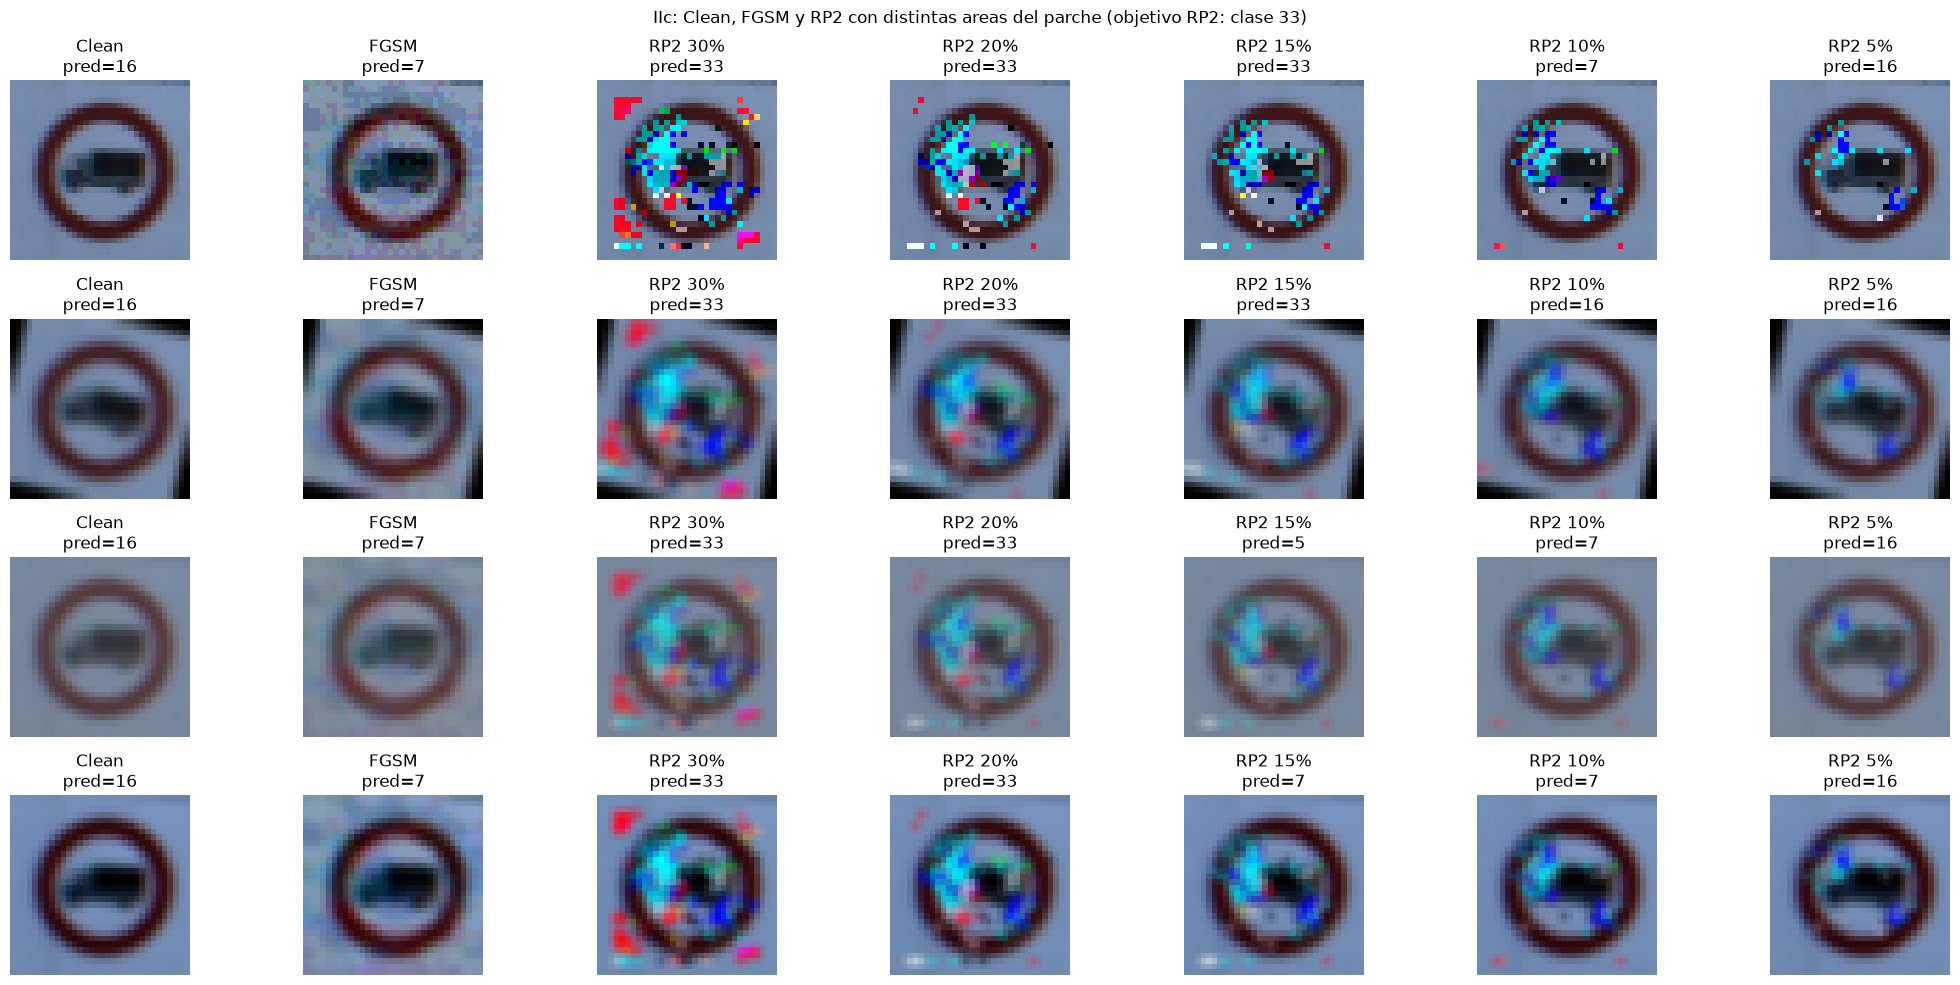

In [184]:
# IIc: efecto visual de reducir el area del parche RP2
PATCH_AREAS_FOR_DISPLAY = [0.30, 0.20, 0.15, 0.10, 0.05]

importance_values = importance_map[roi_mask.bool()]
display_variants = [("Clean", demo_image), ("FGSM", demo_fgsm)]

for area_fraction in PATCH_AREAS_FOR_DISPLAY:
    area_mask = rp2_masks[area_fraction]
    area_patch = rp2_patches[area_fraction]
    rp2_area_image = apply_patch(demo_image, area_patch, area_mask)
    display_variants.append((f"RP2 {area_fraction:.0%}", rp2_area_image))

fig, axes = plt.subplots(
    4,
    len(display_variants),
    figsize=(3 * len(display_variants), 10),
)

for row, (condition, _) in enumerate(photographic_conditions(demo_image).items()):
    for column, (method, image) in enumerate(display_variants):
        transformed = photographic_conditions(image)[condition]
        prediction = model(transformed).argmax(dim=1).item()
        axes[row, column].imshow(
            (transformed[0].detach().cpu() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
        )
        axes[row, column].axis("off")
        axes[row, column].set_title(f"{method}\npred={prediction}")

plt.suptitle(
    "IIc: Clean, FGSM y RP2 con distintas areas del parche "
    "(objetivo RP2: clase 33)"
)
plt.tight_layout()
plt.show()

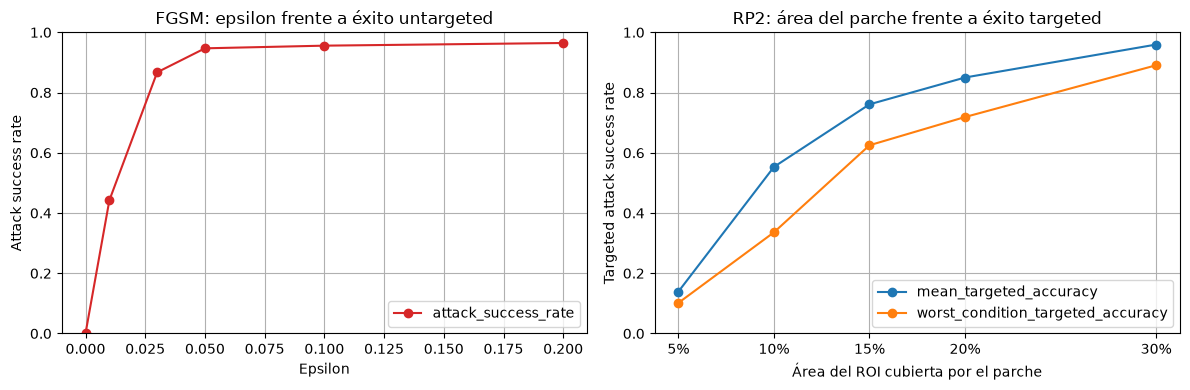

In [185]:
# IIc: intensidad del ataque frente al resultado
# FGSM se controla con epsilon; RP2 se controla con el area del parche.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fgsm_results.plot(
    x="epsilon",
    y="attack_success_rate",
    marker="o",
    ax=axes[0],
    color="tab:red",
    title="FGSM: epsilon frente a éxito untargeted",
)
axes[0].set_xlabel("Epsilon")
axes[0].set_ylabel("Attack success rate")
axes[0].set_ylim(0, 1)
axes[0].grid(True)

rp2_size_summary.sort_values("patch_area_fraction").plot(
    x="patch_area_fraction",
    y=["mean_targeted_accuracy", "worst_condition_targeted_accuracy"],
    marker="o",
    ax=axes[1],
    title="RP2: área del parche frente a éxito targeted",
)
axes[1].set_xlabel("Área del ROI cubierta por el parche")
axes[1].set_ylabel("Targeted attack success rate")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(RP2_PATCH_AREAS)
axes[1].set_xticklabels([f"{area:.0%}" for area in RP2_PATCH_AREAS])
axes[1].grid(True)

plt.tight_layout()
plt.show()